# Chapitre 4 - Cours 3 : Avro, schéma de l'écrivain et schéma du lecteur

Apache Avro est né en 2009 comme sous-projet de Hadoop, parce que les formats à numéros de
champ ne convenaient pas bien à ses usages. Il pousse l'idée du schéma jusqu'au bout : les
données encodées ne contiennent **ni noms, ni numéros, ni types**, seulement des valeurs
concaténées. L'évolution repose alors sur une **résolution** explicite entre le schéma
avec lequel la donnée a été écrite et celui qu'attend le lecteur. Ce cours couvre la
section *Avro* (*The writer's schema and the reader's schema*, *Schema evolution rules*,
*But what is the writer's schema?*, *Dynamically generated schemas*, *Code generation and dynamically typed languages*) et la
section *The Merits of Schemas*.

**Plan.**

1. Un schéma sans numéros : 32 octets.
2. Schéma de l'écrivain, schéma du lecteur et résolution.
3. Les règles d'évolution, testées.
4. Mais quel est le schéma de l'écrivain ? Fichiers, registres, connexions.
5. Des schémas générés dynamiquement.
6. Les mérites des schémas : bilan comparatif des formats.

In [1]:
import copy
import gzip
import json
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import encoding as E
from ddia.encoding import PbField, PbMessage
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
R = E.EXAMPLE_RECORD
W = E.PERSON_AVRO

## 1. Un schéma sans numéros (section *Avro*)

Avro a deux langages de schéma : Avro IDL, pour les humains, et une représentation JSON,
plus facile à traiter par programme. Notre enregistrement s'écrit, en IDL :

```
record Person {
    string               userName;
    union { null, long } favoriteNumber = null;
    array<string>        interests;
}
```

et en JSON (c'est la forme que manipule notre module, `E.PERSON_AVRO`) :

In [2]:
print(json.dumps(W, indent=2))

{
  "type": "record",
  "name": "Person",
  "fields": [
    {
      "name": "userName",
      "type": "string"
    },
    {
      "name": "favoriteNumber",
      "type": [
        "null",
        "long"
      ],
      "default": null
    },
    {
      "name": "interests",
      "type": {
        "type": "array",
        "items": "string"
      }
    }
  ]
}


Pas de numéro de champ. Le champ `favoriteNumber` est une **union** de `null` et `long`
avec `null` pour valeur par défaut : c'est ainsi qu'Avro exprime « facultatif ». Encodons.

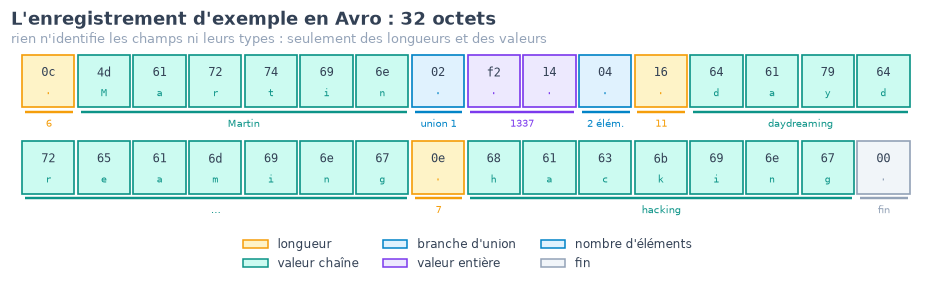

In [3]:
trace = []
av = E.avro_encode(R, W, trace)
fig = E.draw_byte_map(av, trace, title=f"L'enregistrement d'exemple en Avro : {len(av)} octets", per_row=16,
                      subtitle_text="rien n'identifie les champs ni leurs types : seulement des longueurs et des valeurs")
E.byte_legend(fig.axes[0], ["length", "str", "union", "int", "count", "end"], loc="upper center",
              bbox_to_anchor=(0.5, 0.0), ncol=3)
plt.tight_layout(); plt.show()

32 octets, le plus compact de tous. Une chaîne est une longueur (varint zigzag : `0c` =
6) suivie des octets UTF-8 ; l'union commence par l'indice de sa branche (`02` = branche
1, `long`) ; un tableau est une suite de blocs (`04` = 2 éléments, puis `00` = fin).
Mais **rien** ne dit que `0c` est une longueur de chaîne plutôt qu'un entier : pour
décoder, il faut parcourir les champs **dans l'ordre du schéma** et lire chacun selon son
type. Conséquence : il faut exactement le schéma avec lequel la donnée a été écrite.
Essayons de décoder ces 32 octets avec un autre schéma, où l'ordre des champs diffère.

In [4]:
autre_ordre = {"type": "record", "name": "Person", "fields": [W["fields"][1], W["fields"][0], W["fields"][2]]}
try:
    print(E.avro_decode(av, autre_ordre))
except E.AvroError as exc:
    print("échec :", exc)
entiers = {"type": "record", "name": "Person", "fields": [{"name": "a", "type": "long"}, {"name": "b", "type": "long"},
                                                         {"name": "c", "type": "long"}]}
try:
    print("lu comme trois entiers :", E.avro_decode(av[:3], entiers))
except E.AvroError as exc:
    print("échec :", exc)

échec : indice de branche 6 hors de l'union de l'écrivain
lu comme trois entiers : {'a': 6, 'b': -39, 'c': -49}


Avec le mauvais schéma, on obtient au mieux une erreur, au pire des valeurs absurdes
(les trois premiers octets « lus comme des entiers » donnent 6, -39 et -49 : la longueur
de `Martin` puis ses deux premières lettres, décodées en zigzag). Avro tranche ce problème en exigeant que le
lecteur **connaisse le schéma de l'écrivain**.

> **À retenir.** L'encodage Avro n'est qu'une concaténation de valeurs (varints zigzag,
> chaînes préfixées par leur longueur, indices de branche d'union) : 32 octets pour
> l'exemple. Sans le schéma exact de l'écrivain, les octets sont indéchiffrables.